Week 6 libraries loaded. Time to plant some trees!
Checking the first few rows:
         date  open   high   low  close  volume
0  2000-08-30  4.65  4.815  4.63  4.805   34954
1  2000-08-31  4.82  4.870  4.74  4.780   25787
2  2000-09-01  4.75  4.860  4.75  4.835     113
3  2000-09-05  4.85  4.975  4.84  4.960   26096
4  2000-09-06  4.99  5.110  4.96  5.065   32764

--- Single Decision Tree Results ---
Test R-squared:  0.9961
Test MSE error:  0.0192

--- Random Forest Results ---
Test R-squared:  0.9984
Test MSE error:  0.0080


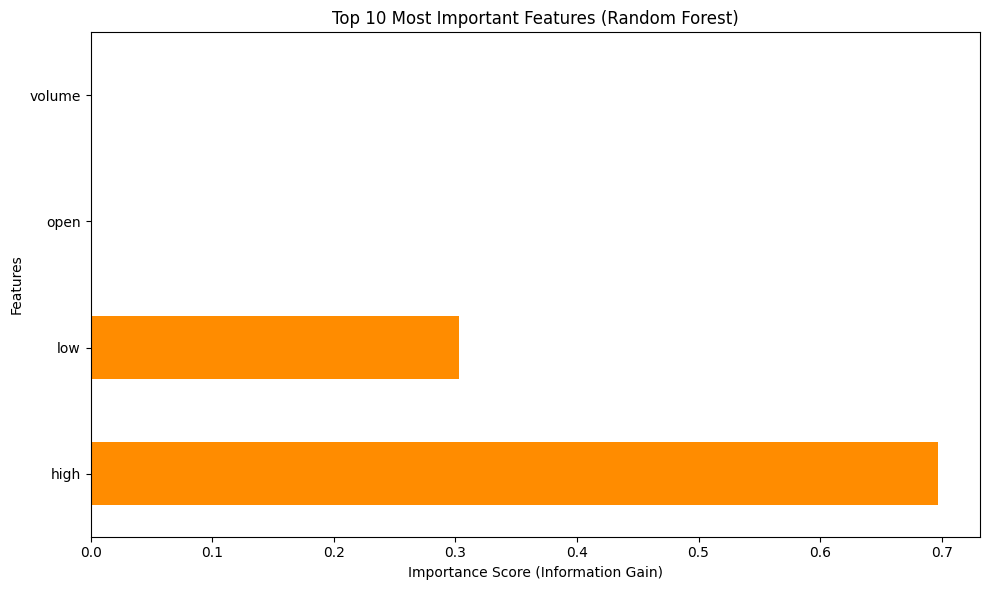

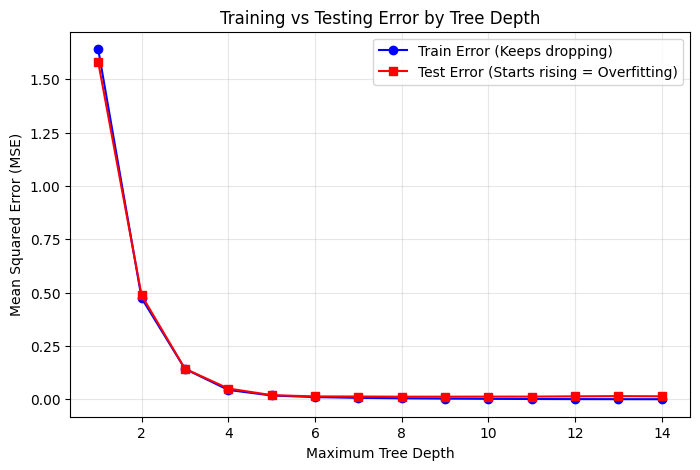

In [1]:
# Step 1: Get our libraries ready for Week 6 (Trees and Forests!)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

print("Week 6 libraries loaded. Time to plant some trees!")

# Step 2: Load our main gas dataset from the class GitHub
link_gas = 'https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv'
df_gas = pd.read_csv(link_gas)

print("Checking the first few rows:")
print(df_gas.head())

# Step 3: Pick the target and drop columns we don't need
# Dropping 'date' because our model doesn't know how to do math on text strings,
# and setting 'close' as our target price.
y_name = 'close'
X = df_gas.drop(columns=['date', y_name])
y = df_gas[y_name]

# Convert any text/category columns into numbers (dummy variables) just in case
X = pd.get_dummies(X, drop_first=True)

# Split the data into Train and Test sets to prevent overfitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Train a single Decision Tree
# max_depth=5 stops the tree from growing too deep and just memorizing the training data.
my_tree = DecisionTreeRegressor(max_depth=5, random_state=42)
my_tree.fit(X_train, y_train)

# See how well the single tree guessed
tree_guesses = my_tree.predict(X_test)
print("\n--- Single Decision Tree Results ---")
print(f"Test R-squared:  {r2_score(y_test, tree_guesses):.4f}")
print(f"Test MSE error:  {mean_squared_error(y_test, tree_guesses):.4f}")

# Step 5: Train a Random Forest (a whole bunch of trees together!)
# Using 100 trees (n_estimators) to vote on the best answer. This fixes the overfitting from a single tree.
my_forest = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
my_forest.fit(X_train, y_train)

# See how much better the forest does compared to the single tree
forest_guesses = my_forest.predict(X_test)
print("\n--- Random Forest Results ---")
print(f"Test R-squared:  {r2_score(y_test, forest_guesses):.4f}")
print(f"Test MSE error:  {mean_squared_error(y_test, forest_guesses):.4f}")

# Step 6: Draw a feature importance chart for the milestone report
# This is the best part—it shows us exactly which variables matter the most for the price!
plt.figure(figsize=(10, 6))

# Grab the scores from our forest model and match them to our column names
importance_scores = pd.Series(my_forest.feature_importances_, index=X.columns)

# Plot the top 10 most important features
importance_scores.nlargest(10).plot(kind='barh', color='darkorange')
plt.title('Top 10 Most Important Features (Random Forest)')
plt.xlabel('Importance Score (Information Gain)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# Extra coding for Milestone One Tree Depth vs Error (Overfitting Check)
train_errors = []
test_errors = []
depths = range(1, 15) # Testing tree depths from 1 to 14

for d in depths:
    temp_tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    temp_tree.fit(X_train, y_train)
    train_errors.append(mean_squared_error(y_train, temp_tree.predict(X_train)))
    test_errors.append(mean_squared_error(y_test, temp_tree.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_errors, label='Train Error (Keeps dropping)', color='blue', marker='o')
plt.plot(depths, test_errors, label='Test Error (Starts rising = Overfitting)', color='red', marker='s')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Training vs Testing Error by Tree Depth')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()